# Swiggy Food Delivery Data Analysis

## Project Overview
This project explores Swiggy food delivery data using Python to understand customer ordering patterns, food preferences, restaurant performance, delivery efficiency and customer satisfaction.

## Project Objectives
1. Understand overall order and customer patterns.
2. Explore relationships between customer orders and delivery performance.
3. Compare business performance across cities, restaurants and food categories.
4. Identify ordering trends and suggest business improvements.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Analysis Approach
Data inspection, data cleaning, exploratory data analysis (EDA), statistical analysis and data visualization.

In [3]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Display all columns when viewing datasets
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
import micropip
await micropip.install("seaborn")

In [4]:
# Load the Swiggy dataset
df = pd.read_csv("Swiggy Food Delivery Data Analysis.csv")

# Display the first five rows
df.head()

,Order_ID,Customer_ID,City,Restaurant_Name,Food_Category,Order_Date,Order_Time,Order_Value,Delivery_Time,Rating,Payment_Method,Order_Status,Distance_km,Discount,Delivery_Fee
0,SWG100000,CUST37343,Ahmedabad,Punjabi Tadka,North Indian,2025-04-13,18:41,260.47,22.0,4.3,Credit Card,Delivered,2.6,0.00,31.07
1,SWG100001,CUST45683,Bengaluru,Biryani Blues,Biryani,2025-12-15,18:54,1012.15,29.0,3.6,UPI,Delivered,1.3,53.06,16.23
2,SWG100002,CUST43263,Kolkata,Udupi Express,South Indian,2025-09-28,21:07,485.66,58.0,4.0,Credit Card,Delivered,9.0,0.00,49.23
3,SWG100003,CUST42294,Pune,Delhi Darbar,North Indian,2025-04-17,19:29,264.34,90.0,2.9,UPI,Delivered,18.7,62.57,93.53
4,SWG100004,CUST59025,Bengaluru,Big Bite,Burgers,2025-03-13,12:38,819.00,37.0,4.0,Credit Card,Delivered,6.2,0.00,42.31


In [5]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (15000, 15)

Column names:
['Order_ID', 'Customer_ID', 'City', 'Restaurant_Name', 'Food_Category', 'Order_Date', 'Order_Time', 'Order_Value', 'Delivery_Time', 'Rating', 'Payment_Method', 'Order_Status', 'Distance_km', 'Discount', 'Delivery_Fee']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         15000 non-null  str    
 1   Customer_ID      15000 non-null  str    
 2   City             15000 non-null  str    
 3   Restaurant_Name  15000 non-null  str    
 4   Food_Category    15000 non-null  str    
 5   Order_Date       15000 non-null  str    
 6   Order_Time       15000 non-null  str    
 7   Order_Value      15000 non-null  float64
 8   Delivery_Time    15000 non-null  float64
 9   Rating           15000 non-null  float64
 10  Payment_Method   15000 non-null  str    
 11  Order_Status    

In [6]:
# Convert date and time columns
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Order_Time'] = pd.to_datetime(
    df['Order_Time'], format='%H:%M'
).dt.time

# Verify the changes
print(df[['Order_Date', 'Order_Time']].dtypes)

# Display sample records
df[['Order_Date', 'Order_Time']].head()

Order_Date    datetime64[us]
Order_Time            object
dtype: object


,Order_Date,Order_Time
0,2025-04-13,18:41:00
1,2025-12-15,18:54:00
2,2025-09-28,21:07:00
3,2025-04-17,19:29:00
4,2025-03-13,12:38:00


In [7]:
# Summary statistics for numerical columns
df.describe()

,Order_Date,Order_Value,Delivery_Time,Rating,Distance_km,Discount,Delivery_Fee
count,15000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,2025-07-01 08:27:50.400000,611.922017,43.233000,3.985740,5.288907,28.290541,41.280385
min,2025-01-01 00:00:00,109.480000,12.000000,1.700000,0.500000,0.000000,10.000000
25%,2025-04-01 00:00:00,399.567500,32.000000,3.700000,3.000000,0.000000,31.827500
50%,2025-06-30 00:00:00,558.460000,41.000000,4.000000,4.600000,0.000000,38.985000
75%,2025-10-01 00:00:00,766.832500,52.000000,4.300000,6.900000,50.050000,48.572500
max,2025-12-31 00:00:00,2280.420000,90.000000,5.000000,20.000000,149.980000,111.350000
std,NaN,287.721340,15.409794,0.477909,3.141607,45.378103,13.526014


Order_Status
Delivered    14083
Cancelled      697
Returned       220
Name: count, dtype: int64


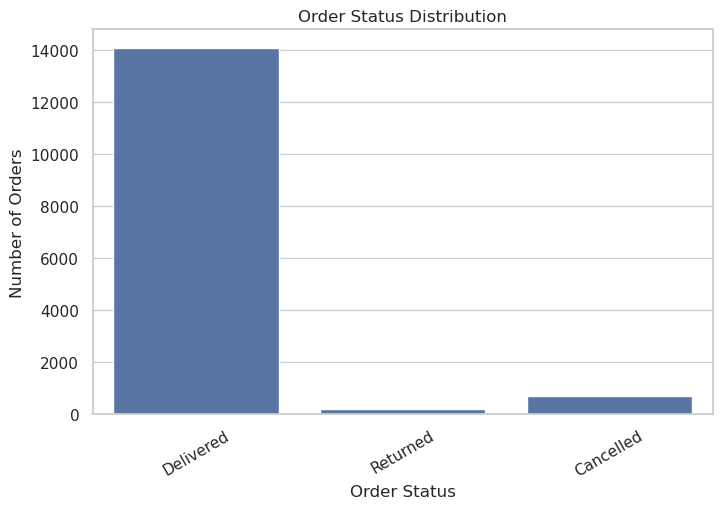

In [8]:
# Count orders by status
status_counts = df['Order_Status'].value_counts()

print(status_counts)

# Visualize order status distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Order_Status')
plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.show()

Food_Category
North Indian    2402
Biryani         1986
South Indian    1799
Chinese         1788
Pizza           1496
Burgers         1319
Desserts        1210
Street Food     1176
Healthy          943
Continental      881
Name: count, dtype: int64


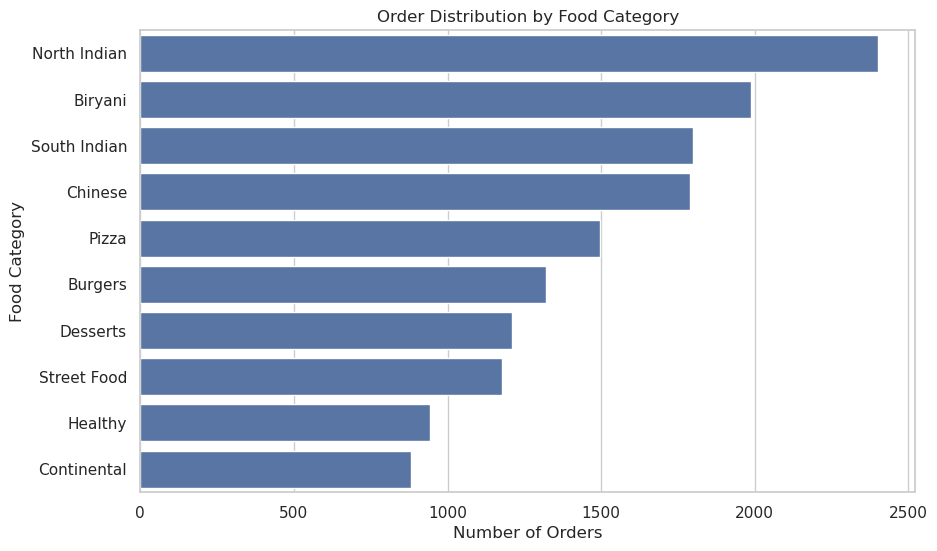

In [10]:
# Count orders by food category
category_counts = df['Food_Category'].value_counts()

print(category_counts)

# Visualize food category distribution
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    y='Food_Category',
    order=category_counts.index
)
plt.title('Order Distribution by Food Category')
plt.xlabel('Number of Orders')
plt.ylabel('Food Category')
plt.show()

City
Hyderabad    1574
Lucknow      1520
Mumbai       1515
Pune         1512
Ahmedabad    1509
Jaipur       1481
Kolkata      1478
Delhi        1478
Bengaluru    1471
Chennai      1462
Name: count, dtype: int64


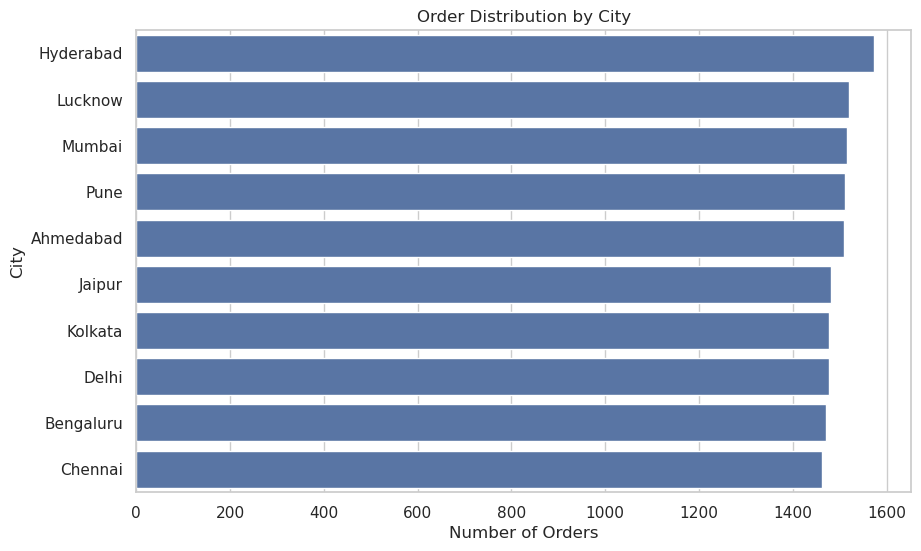

In [11]:
# Count orders by city
city_counts = df['City'].value_counts()

print(city_counts)

# Visualize city-wise order distribution
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    y='City',
    order=city_counts.index
)
plt.title('Order Distribution by City')
plt.xlabel('Number of Orders')
plt.ylabel('City')
plt.show()

Food_Category
North Indian    619.570062
Biryani         619.330836
South Indian    612.878155
Desserts        612.237802
Street Food     611.613648
Pizza           611.013643
Burgers         608.301653
Continental     606.666141
Chinese         605.375872
Healthy         598.820276
Name: Order_Value, dtype: float64


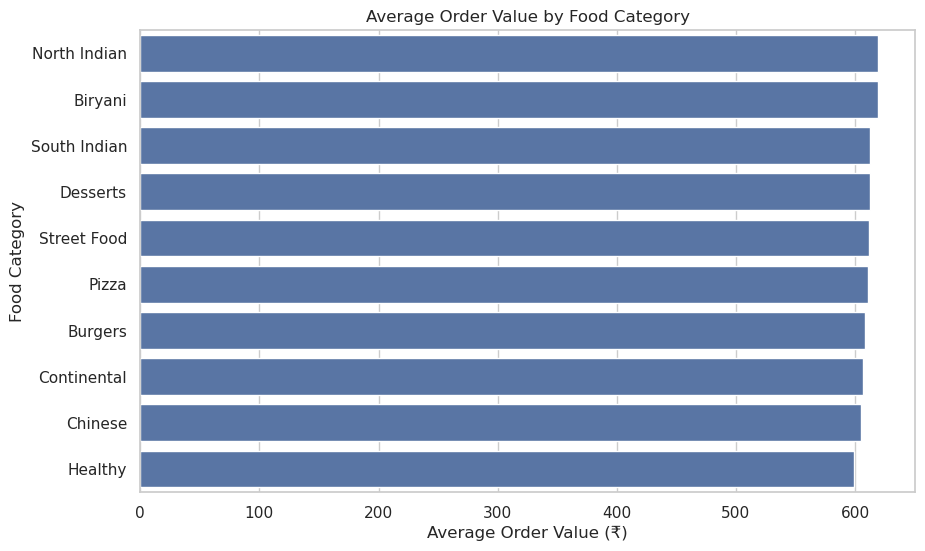

In [13]:
# Calculate average order value by food category
avg_category_value = (
    df.groupby('Food_Category')['Order_Value']
    .mean()
    .sort_values(ascending=False))

print(avg_category_value)

# Visualize average order value
plt.figure(figsize=(10, 6))
sns.barplot(
    x=avg_category_value.values,
    y=avg_category_value.index
)
plt.title('Average Order Value by Food Category')
plt.xlabel('Average Order Value (₹)')
plt.ylabel('Food Category')
plt.show()

Payment_Method
UPI            6276
Credit Card    3306
Debit Card     2453
Cash           1807
Wallet         1158
Name: count, dtype: int64


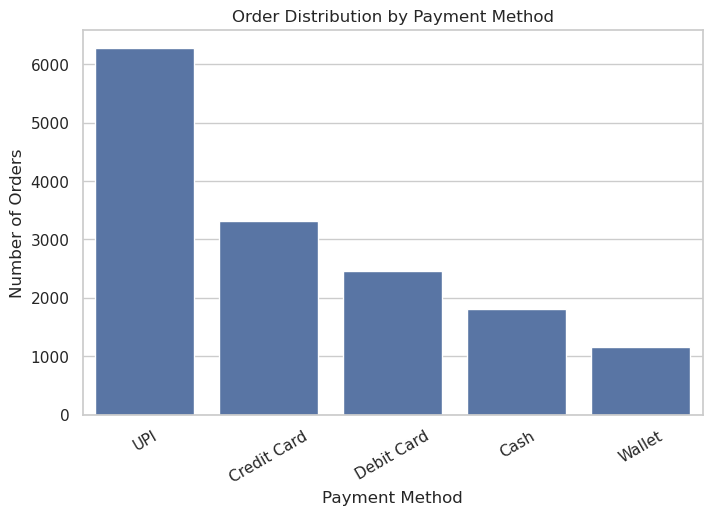

In [15]:
# Count orders by payment method
payment_counts = df['Payment_Method'].value_counts()

print(payment_counts)

# Visualize payment method distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='Payment_Method',
    order=payment_counts.index)
plt.title('Order Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.show()

              count   mean  median   min   max
Order_Status                                  
Cancelled       697  43.24    41.0  12.0  90.0
Delivered     14083  43.21    41.0  12.0  90.0
Returned        220  44.64    42.5  12.0  90.0


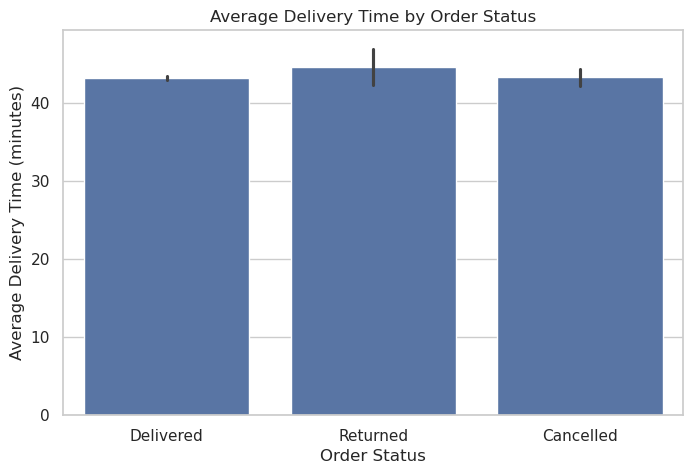

In [16]:
# Average delivery time by order status
delivery_analysis = df.groupby('Order_Status')['Delivery_Time'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print(delivery_analysis.round(2))

# Visualize average delivery time by order status
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df,
    x='Order_Status',
    y='Delivery_Time',
    estimator='mean')
plt.title('Average Delivery Time by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Average Delivery Time (minutes)')
plt.show()

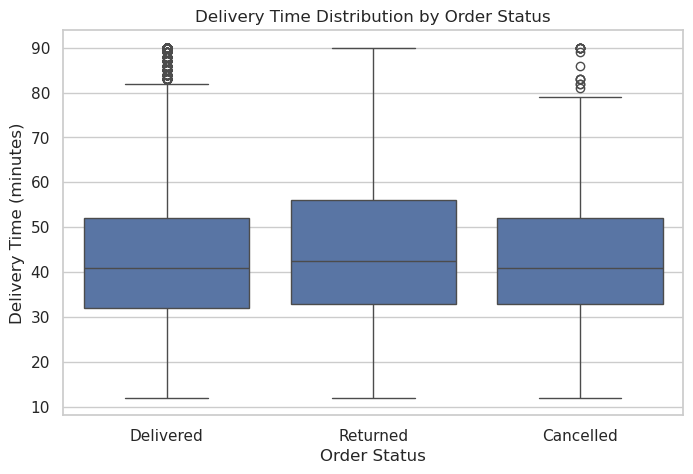

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Order_Status', y='Delivery_Time')

plt.title('Delivery Time Distribution by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Delivery Time (minutes)')
plt.show()

In [20]:
# Select numerical columns for correlation analysis
numeric_df = df.select_dtypes(include=['number'])

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Display correlation values
print(correlation_matrix.round(2))

               Order_Value  Delivery_Time  Rating  Distance_km  Discount  \
Order_Value           1.00           0.00   -0.02        -0.00      0.01   
Delivery_Time         0.00           1.00   -0.39         0.84      0.01   
Rating               -0.02          -0.39    1.00        -0.33     -0.01   
Distance_km          -0.00           0.84   -0.33         1.00      0.00   
Discount              0.01           0.01   -0.01         0.00      1.00   
Delivery_Fee         -0.01           0.78   -0.30         0.93      0.00   

               Delivery_Fee  
Order_Value           -0.01  
Delivery_Time          0.78  
Rating                -0.30  
Distance_km            0.93  
Discount               0.00  
Delivery_Fee           1.00  


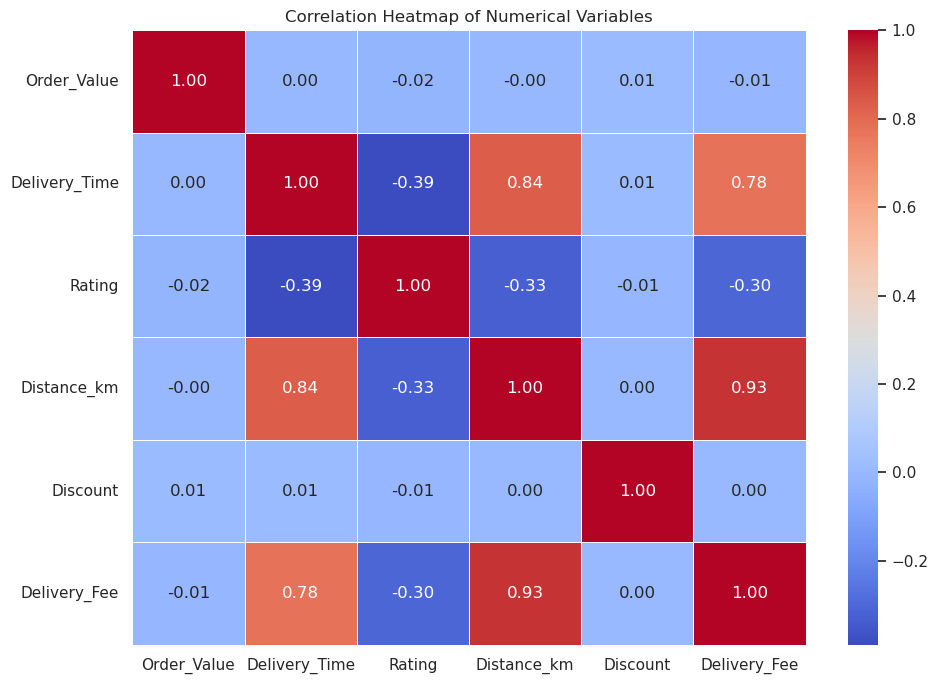

In [22]:
# Correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

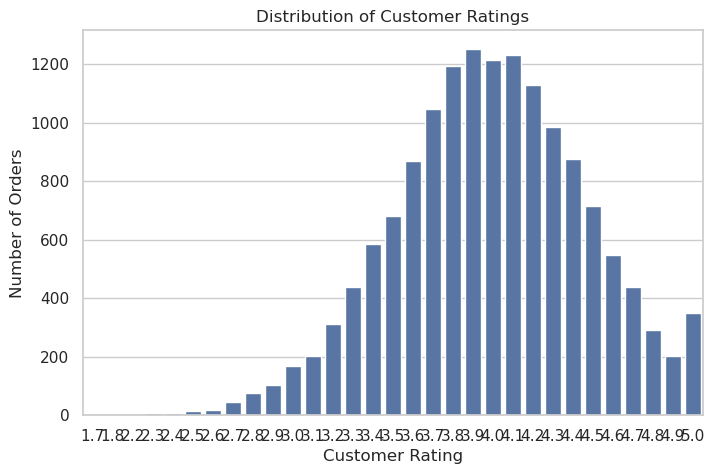

Average Rating by Food Category:
Food_Category
Street Food     4.00
Burgers         3.99
Healthy         3.99
Chinese         3.99
Pizza           3.99
Biryani         3.99
South Indian    3.98
North Indian    3.98
Continental     3.98
Desserts        3.98
Name: Rating, dtype: float64


In [23]:
# Distribution of customer ratings

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Rating')

plt.title('Distribution of Customer Ratings')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Orders')
plt.show()

# Average rating by food category
rating_category = df.groupby('Food_Category')['Rating'].mean().sort_values(ascending=False)

print("Average Rating by Food Category:")
print(rating_category.round(2))

Top 10 Restaurants by Number of Orders:
Restaurant_Name
Punjabi Tadka       634
The Curry House     600
Delhi Darbar        591
Shahi Rasoi         577
Dum Biryani         511
Biryani Hub         499
Hyderabadi House    492
Biryani Blues       484
South Spice         481
Madras Cafe         476
Name: count, dtype: int64


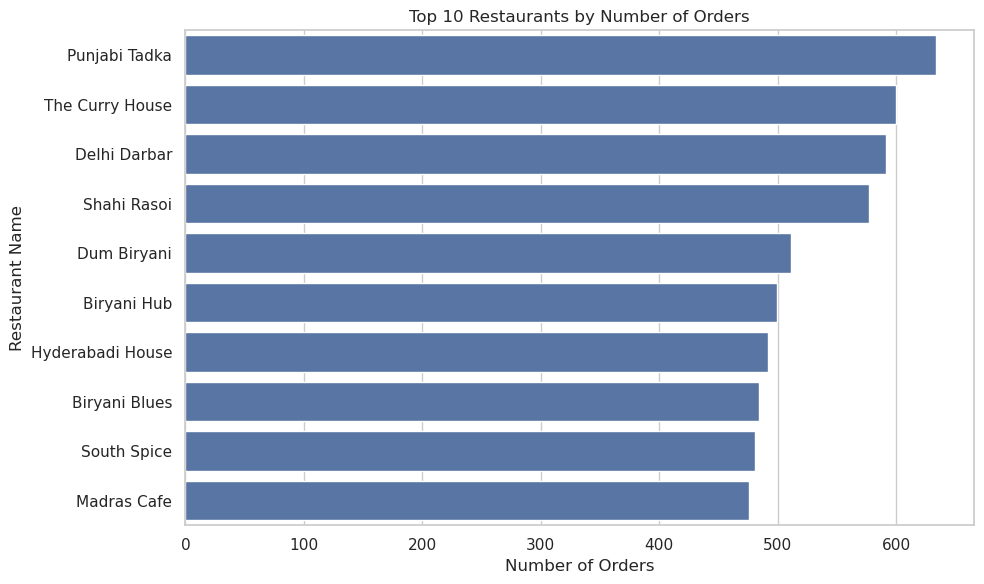

In [25]:
# Top 10 restaurants by number of orders

restaurant_orders = (
    df['Restaurant_Name']
    .value_counts()
    .head(10))

print("Top 10 Restaurants by Number of Orders:")
print(restaurant_orders)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=restaurant_orders.values,
    y=restaurant_orders.index)

plt.title('Top 10 Restaurants by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Restaurant Name')
plt.tight_layout()
plt.show()

Top 10 Restaurants by Average Order Value:
Restaurant_Name
Salad Story      643.23
Biryani Hub      638.68
China Town       632.71
Food Factory     631.50
Pizza Palace     631.48
Shahi Rasoi      628.91
Creamy Corner    627.32
Big Bite         626.42
Food Cart        624.47
South Spice      622.40
Name: Order_Value, dtype: float64


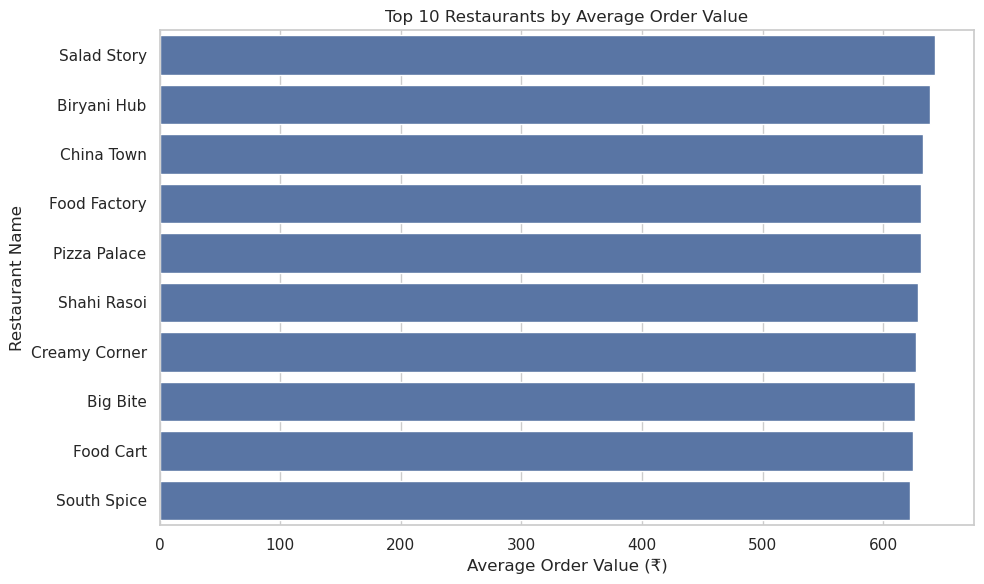

In [27]:
# Average order value by restaurant

restaurant_value = (
    df.groupby('Restaurant_Name')['Order_Value']
    .mean()
    .sort_values(ascending=False)
    .head(10))

print("Top 10 Restaurants by Average Order Value:")
print(restaurant_value.round(2))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=restaurant_value.values,
    y=restaurant_value.index)

plt.title('Top 10 Restaurants by Average Order Value')
plt.xlabel('Average Order Value (₹)')
plt.ylabel('Restaurant Name')
plt.tight_layout()
plt.show()

Monthly Order Volume:
Month
2025-01    1297
2025-02    1152
2025-03    1290
2025-04    1265
2025-05    1258
2025-06    1245
2025-07    1227
2025-08    1265
2025-09    1223
2025-10    1264
2025-11    1254
2025-12    1260
Freq: M, Name: Order_ID, dtype: int64


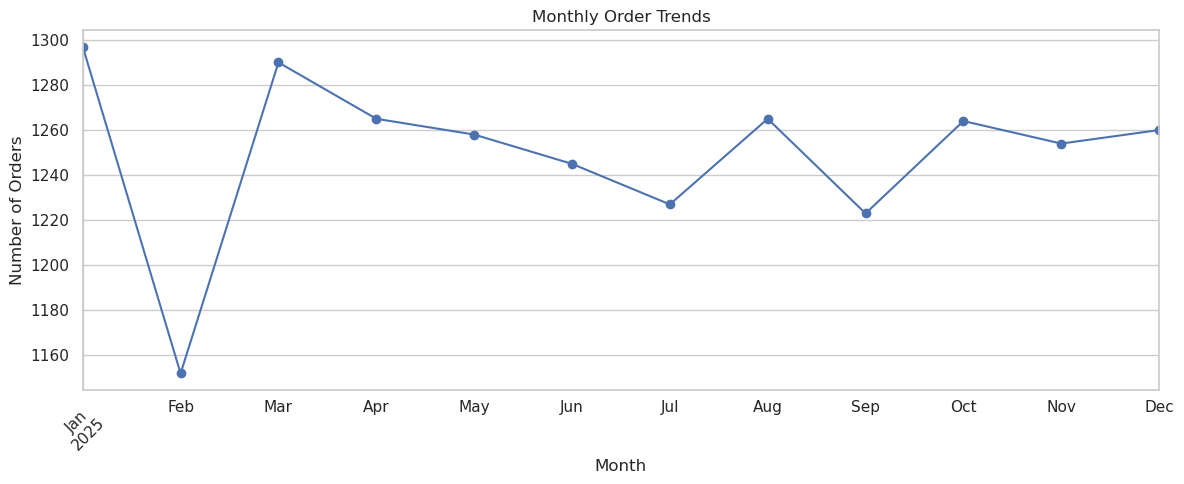

In [28]:
# Convert order dates into monthly periods
df['Month'] = df['Order_Date'].dt.to_period('M')

# Calculate monthly order volume
monthly_orders = df.groupby('Month')['Order_ID'].count()

print("Monthly Order Volume:")
print(monthly_orders)

# Visualize monthly order trends
plt.figure(figsize=(12, 5))

monthly_orders.plot(kind='line', marker='o')

plt.title('Monthly Order Trends')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Average Delivery Time by Month:
Month
2025-01    43.19
2025-02    43.11
2025-03    43.41
2025-04    42.76
2025-05    43.41
2025-06    42.87
2025-07    43.20
2025-08    43.92
2025-09    43.28
2025-10    42.54
2025-11    44.09
2025-12    43.02
Freq: M, Name: Delivery_Time, dtype: float64


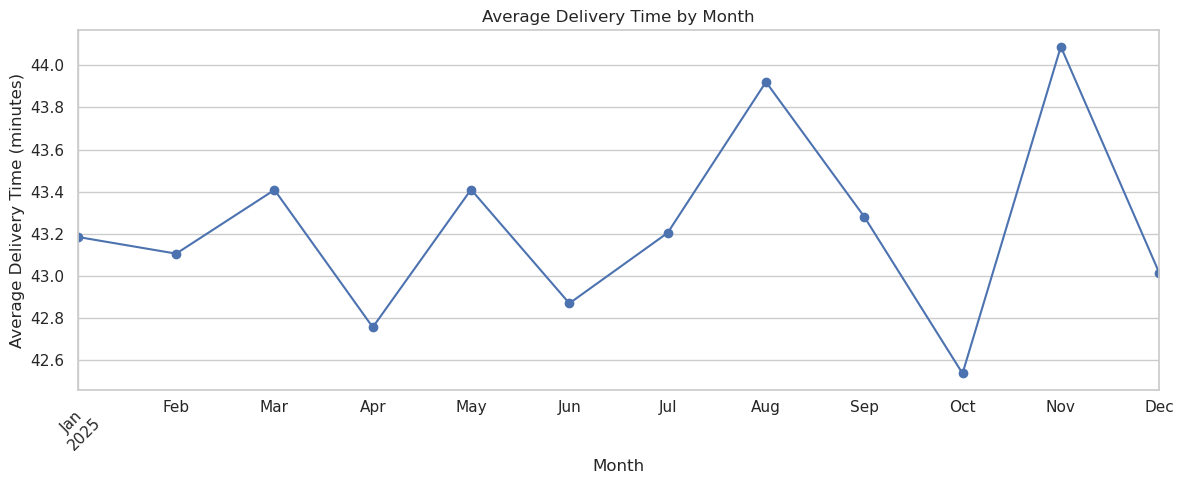

In [29]:
# Calculate average delivery time by month

monthly_delivery = df.groupby('Month')['Delivery_Time'].mean()

print("Average Delivery Time by Month:")
print(monthly_delivery.round(2))

# Visualize monthly average delivery time

plt.figure(figsize=(12, 5))

monthly_delivery.plot(kind='line', marker='o')

plt.title('Average Delivery Time by Month')
plt.xlabel('Month')
plt.ylabel('Average Delivery Time (minutes)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Average Delivery Time by City:
City
Lucknow      43.89
Chennai      43.72
Kolkata      43.37
Bengaluru    43.31
Hyderabad    43.30
Ahmedabad    43.23
Pune         43.13
Delhi        42.82
Jaipur       42.80
Mumbai       42.77
Name: Delivery_Time, dtype: float64


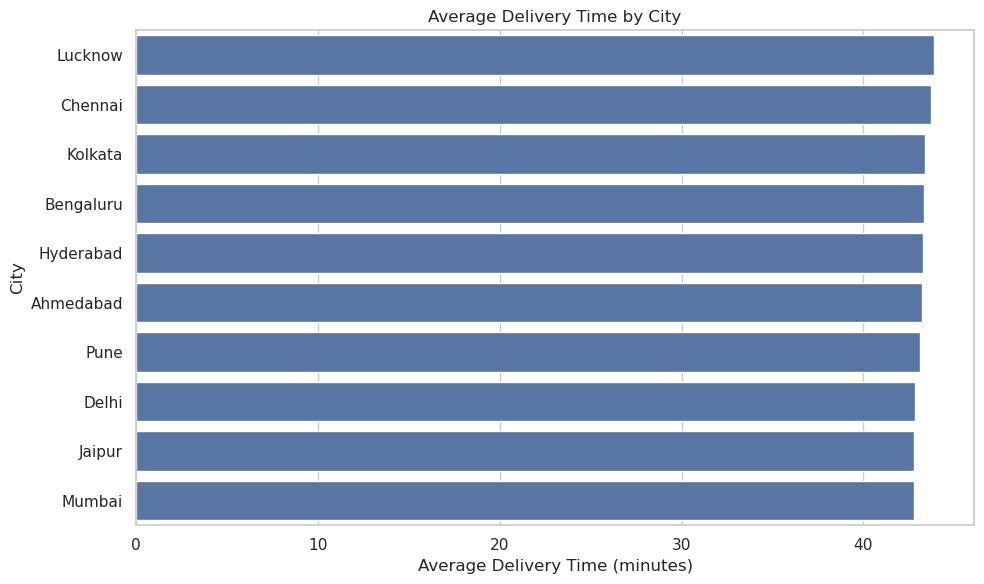

In [34]:
# Calculate average delivery time by city

city_delivery = (
    df.groupby('City')['Delivery_Time']
    .mean()
    .sort_values(ascending=False))


print("Average Delivery Time by City:")
print(city_delivery.round(2))

# Visualize average delivery time by city

plt.figure(figsize=(10, 6))

sns.barplot(x=city_delivery.values, y=city_delivery.index)

plt.title('Average Delivery Time by City')
plt.xlabel('Average Delivery Time (minutes)')
plt.ylabel('City')
plt.tight_layout()
plt.show()

Orders by Day of the Week:
Day_Name
Monday       2164
Tuesday      2207
Wednesday    2170
Thursday     2133
Friday       2080
Saturday     2085
Sunday       2161
Name: count, dtype: int64


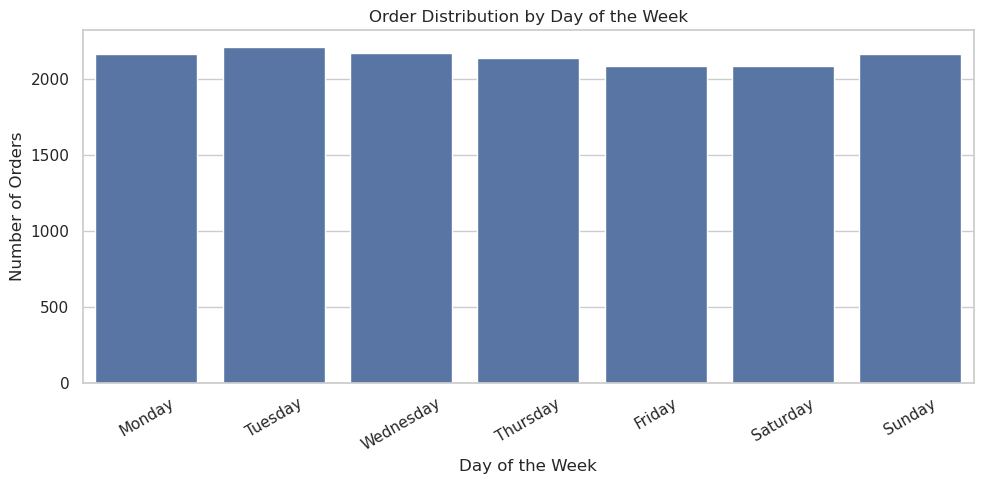

In [35]:
# Analyze order volume by day of the week

df['Day_Name'] = df['Order_Date'].dt.day_name()

day_order = (
    df['Day_Name']
    .value_counts()
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
)

print("Orders by Day of the Week:")
print(day_order)

# Visualize order distribution by day

plt.figure(figsize=(10, 5))

sns.barplot(
    x=day_order.index,
    y=day_order.values
)

plt.title('Order Distribution by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

<ipython-input-36-44c2c72594cc>:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Order_Hour'] = pd.to_datetime(


Orders by Hour:
Order_Hour
10     412
11     420
12     587
13     648
14     816
15     844
16     935
17    1134
18    1438
19    1690
20    1886
21    1693
22    1456
23    1041
Name: count, dtype: int64


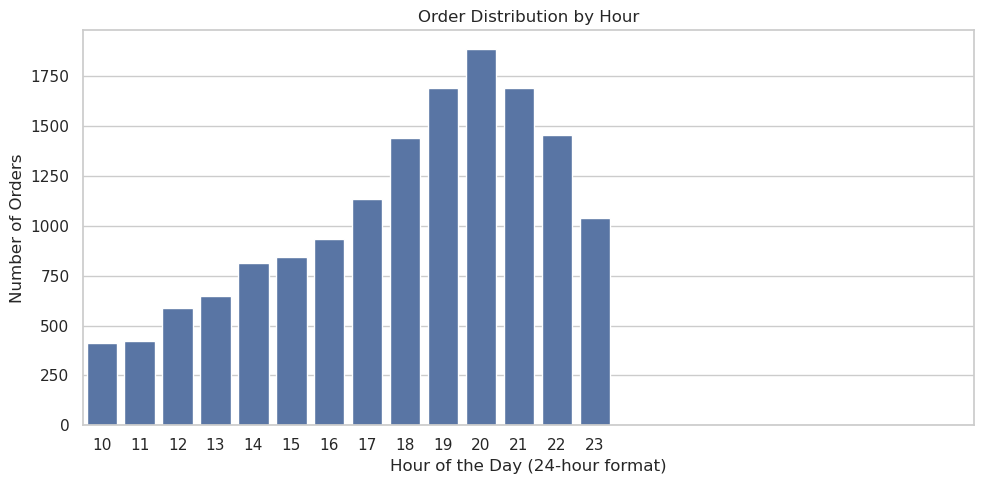

In [36]:
# Extract hour from order time
df['Order_Hour'] = pd.to_datetime(
    df['Order_Time'].astype(str)
).dt.hour

# Count orders by hour
hourly_orders = df['Order_Hour'].value_counts().sort_index()

print("Orders by Hour:")
print(hourly_orders)

# Visualize hourly order trends
plt.figure(figsize=(10, 5))

sns.barplot(
    x=hourly_orders.index,
    y=hourly_orders.values
)

plt.title('Order Distribution by Hour')
plt.xlabel('Hour of the Day (24-hour format)')
plt.ylabel('Number of Orders')
plt.xticks(range(24))
plt.tight_layout()
plt.show()

Food Category Orders by Time Period:
Food_Category  Biryani  Burgers  Chinese  Continental  Desserts  Healthy  \
Time_Period                                                                
Afternoon          515      337      457          217       330      261   
Evening            832      517      734          367       475      370   
Morning            117       86       98           41        70       53   
Night              522      379      499          256       335      259   

Food_Category  North Indian  Pizza  South Indian  Street Food  
Time_Period                                                    
Afternoon               599    370           455          289  
Evening                1002    636           723          492  
Morning                 131     73            98           65  
Night                   670    417           523          330  


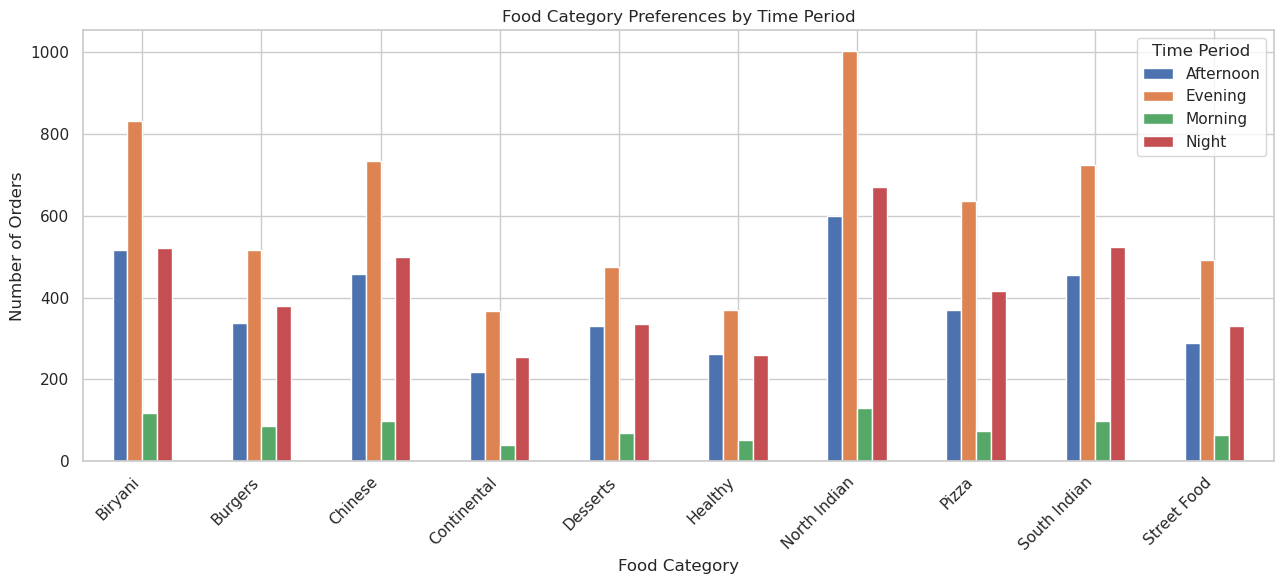

In [37]:
# Create time periods
def get_time_period(hour):
    if 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

df['Time_Period'] = df['Order_Hour'].apply(get_time_period)

# Compare food categories across time periods
category_time = pd.crosstab(
    df['Time_Period'],
    df['Food_Category']
)

print("Food Category Orders by Time Period:")
print(category_time)

# Visualize the comparison
category_time.T.plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title('Food Category Preferences by Time Period')
plt.xlabel('Food Category')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Time Period')
plt.tight_layout()
plt.show()

Average Order Value by City:
City
Chennai      618.70
Pune         616.95
Lucknow      615.82
Ahmedabad    614.72
Delhi        613.60
Bengaluru    612.41
Hyderabad    610.60
Jaipur       609.89
Kolkata      607.95
Mumbai       598.79
Name: Order_Value, dtype: float64


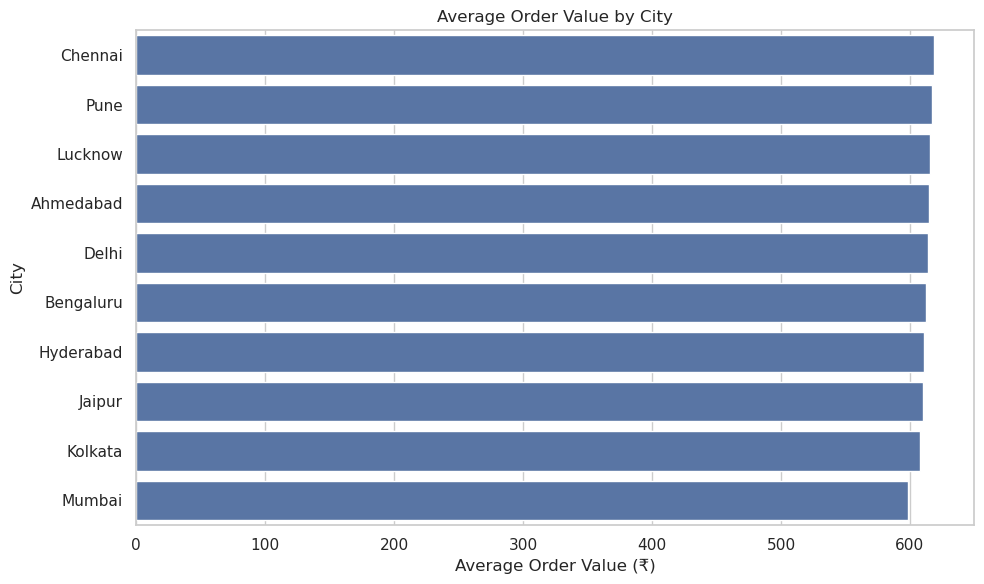

In [38]:
# Calculate average order value by city

city_order_value = (
    df.groupby('City')['Order_Value']
    .mean()
    .sort_values(ascending=False)
)

print("Average Order Value by City:")
print(city_order_value.round(2))

# Visualize average order value by city

plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_order_value.values,
    y=city_order_value.index
)

plt.title('Average Order Value by City')
plt.xlabel('Average Order Value (₹)')
plt.ylabel('City')
plt.tight_layout()
plt.show()

Correlation between Order Value and Delivery Time:
0.001


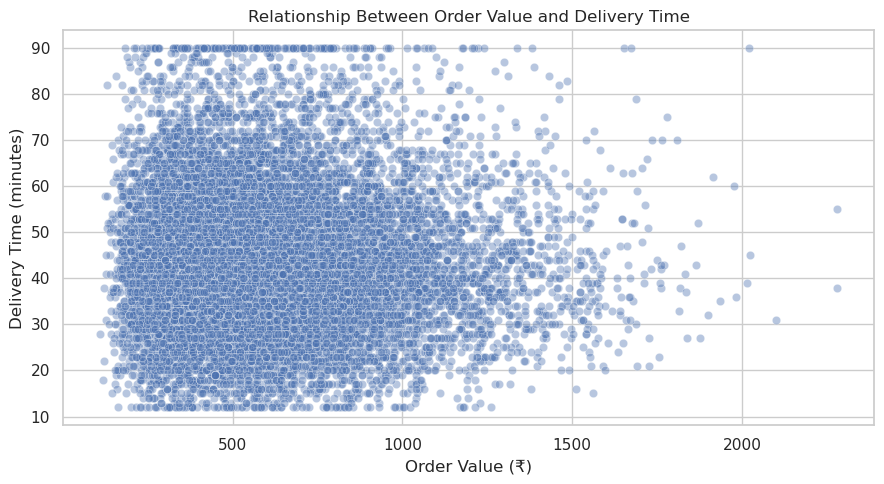

In [39]:
# Relationship between order value and delivery time

correlation = df['Order_Value'].corr(df['Delivery_Time'])

print("Correlation between Order Value and Delivery Time:")
print(round(correlation, 3))

# Scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Order_Value',
    y='Delivery_Time',
    alpha=0.4
)

plt.title('Relationship Between Order Value and Delivery Time')
plt.xlabel('Order Value (₹)')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.show()

Correlation between Delivery Time and Rating:
-0.389


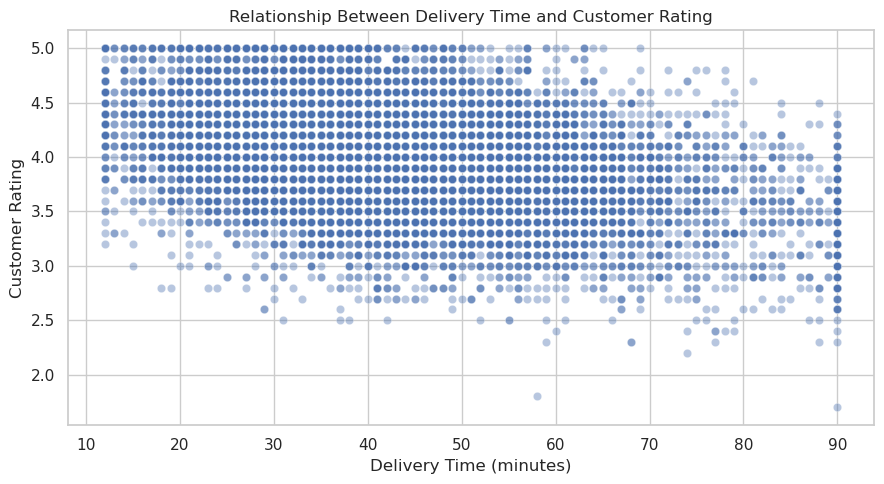

In [42]:
# Correlation between delivery time and customer rating

rating_correlation = df['Delivery_Time'].corr(df['Rating'])

print("Correlation between Delivery Time and Rating:")
print(round(rating_correlation, 3))

# Scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Delivery_Time',
    y='Rating',
    alpha=0.4)

plt.title('Relationship Between Delivery Time and Customer Rating')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Customer Rating')
plt.tight_layout()
plt.show()

Average Customer Rating by City:
City
Jaipur       4.01
Pune         3.99
Ahmedabad    3.99
Bengaluru    3.99
Kolkata      3.99
Chennai      3.99
Mumbai       3.99
Hyderabad    3.98
Delhi        3.98
Lucknow      3.96
Name: Rating, dtype: float64


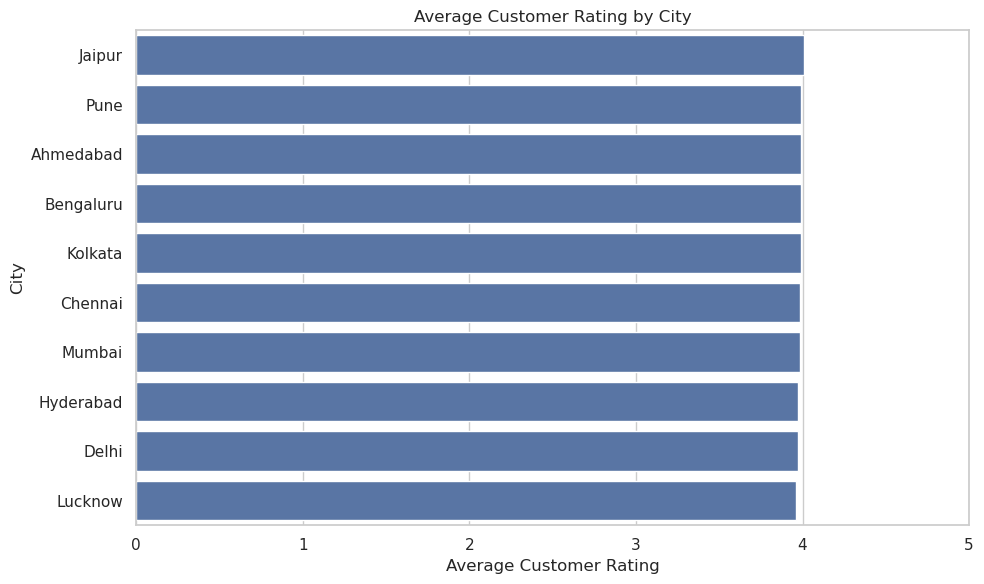

In [41]:
# Calculate average customer rating by city

city_ratings = (
    df.groupby('City')['Rating']
    .mean()
    .sort_values(ascending=False)
)

print("Average Customer Rating by City:")
print(city_ratings.round(2))

# Visualize city-wise ratings

plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_ratings.values,
    y=city_ratings.index
)

plt.title('Average Customer Rating by City')
plt.xlabel('Average Customer Rating')
plt.ylabel('City')
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

Average Rating by City and Food Category:
Food_Category  Biryani  Burgers  Chinese  Continental  Desserts  Healthy  \
City                                                                       
Ahmedabad         3.94     4.00     3.98         3.92      4.06     4.05   
Bengaluru         3.93     4.03     4.01         4.00      4.01     4.05   
Chennai           3.99     4.01     3.99         3.97      3.98     3.93   
Delhi             4.02     4.00     3.95         3.97      3.96     3.98   
Hyderabad         3.97     4.05     3.95         4.01      4.00     3.93   
Jaipur            4.01     4.04     4.02         3.98      3.96     3.95   
Kolkata           4.00     3.95     4.03         3.93      3.97     4.07   
Lucknow           3.97     3.95     3.94         3.99      3.94     3.89   
Mumbai            4.00     3.94     4.03         3.98      3.95     4.02   
Pune              4.00     3.97     4.02         4.01      3.96     4.03   

Food_Category  North Indian  Pizza  South Ind

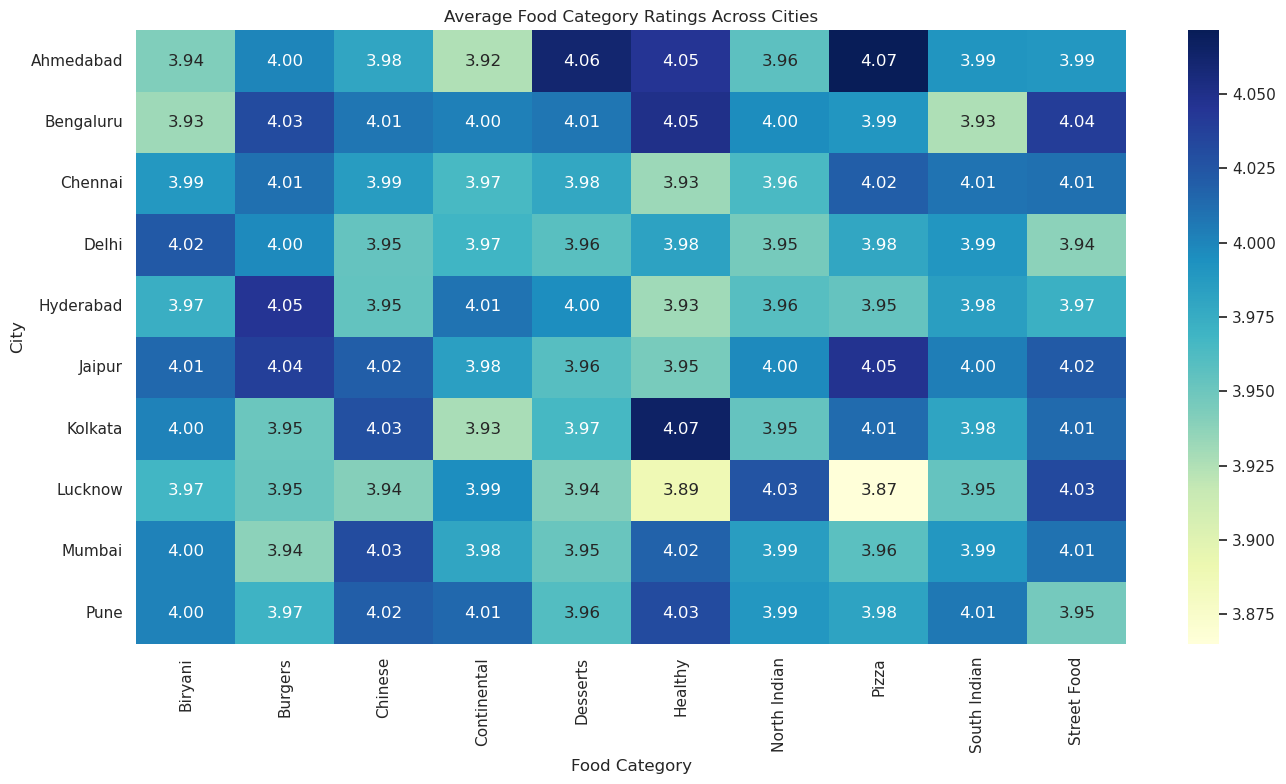

In [44]:
# Average customer rating by city and food category

city_category_ratings = df.pivot_table(
    index='City',
    columns='Food_Category',
    values='Rating',
    aggfunc='mean')

print("Average Rating by City and Food Category:")
print(city_category_ratings.round(2))

# Visualize using a heatmap

plt.figure(figsize=(14, 8))

sns.heatmap(
    city_category_ratings,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu')

plt.title('Average Food Category Ratings Across Cities')
plt.xlabel('Food Category')
plt.ylabel('City')
plt.tight_layout()
plt.show()

Average Order Value by City and Food Category:
Food_Category  Biryani  Burgers  Chinese  Continental  Desserts  Healthy  \
City                                                                       
Ahmedabad       618.13   635.40   576.24       594.30    647.84   611.20   
Bengaluru       622.61   546.06   636.05       601.58    650.38   601.29   
Chennai         611.03   633.38   672.98       582.13    633.17   569.71   
Delhi           603.45   594.98   611.13       615.89    633.16   602.26   
Hyderabad       612.18   618.06   574.15       607.66    583.73   566.06   
Jaipur          612.54   583.77   611.87       586.83    593.29   599.25   
Kolkata         637.42   605.31   588.80       593.22    601.57   597.82   
Lucknow         652.58   591.75   601.99       622.73    593.26   604.00   
Mumbai          607.40   624.64   598.00       616.23    587.44   645.95   
Pune            617.95   642.33   592.09       649.90    608.78   598.68   

Food_Category  North Indian   Pizza  Sou

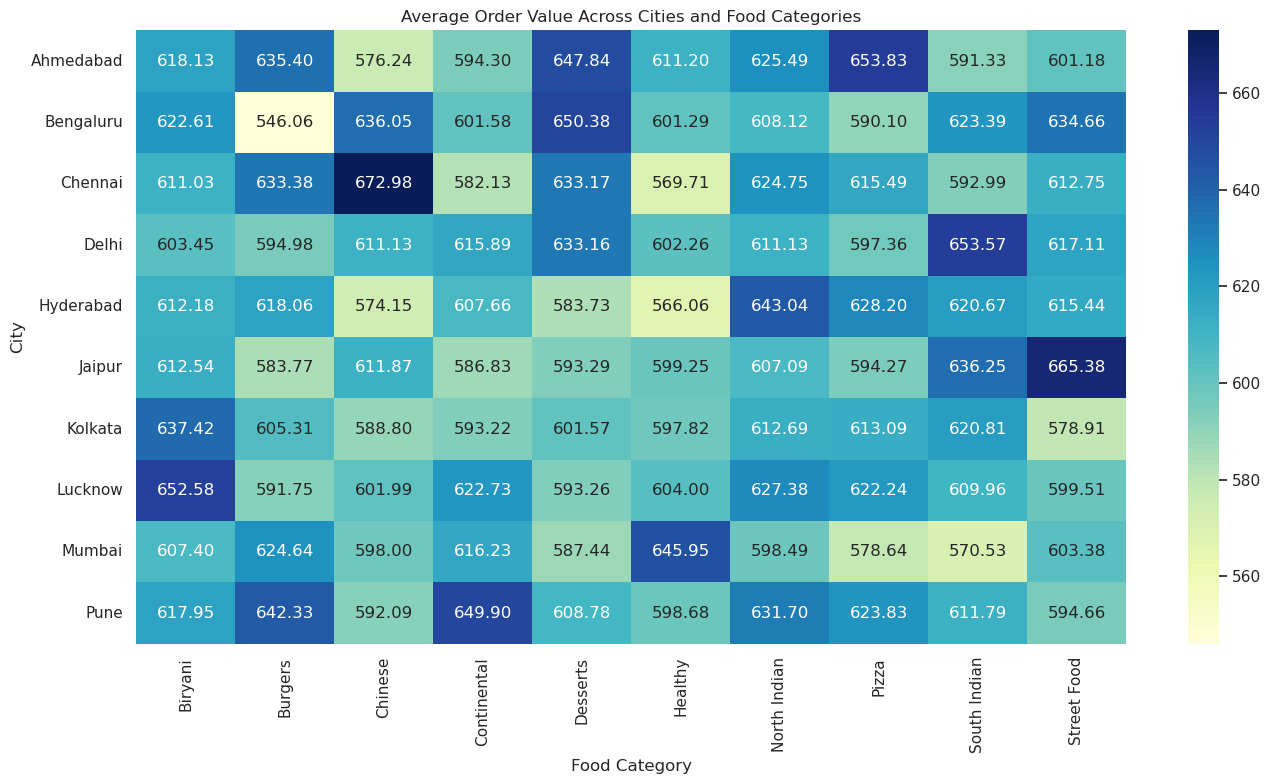

In [45]:
# Average order value by city and food category
city_category_value = df.pivot_table(
    values='Order_Value',
    index='City',
    columns='Food_Category',
    aggfunc='mean'
)

print("Average Order Value by City and Food Category:")
print(city_category_value.round(2))

# Visualize using a heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    city_category_value,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)

plt.title('Average Order Value Across Cities and Food Categories')
plt.xlabel('Food Category')
plt.ylabel('City')
plt.tight_layout()
plt.show()

Restaurant Order Distribution Across Cities:
City              Ahmedabad  Bengaluru  Chennai  Delhi  Hyderabad  Jaipur  \
Restaurant_Name                                                             
Biryani Blues            44         40       56     49         60      42   
Biryani Hub              58         67       38     37         57      44   
Delhi Darbar             65         48       54     52         56      59   
Dum Biryani              38         47       53     71         49      52   
Hyderabadi House         46         41       42     56         55      47   
Madras Cafe              44         46       39     34         49      59   
Punjabi Tadka            80         63       63     49         64      49   
Shahi Rasoi              52         41       57     50         66      63   
South Spice              42         49       47     47         45      54   
The Curry House          60         60       62     54         59      65   

City              Kolkata  Luc

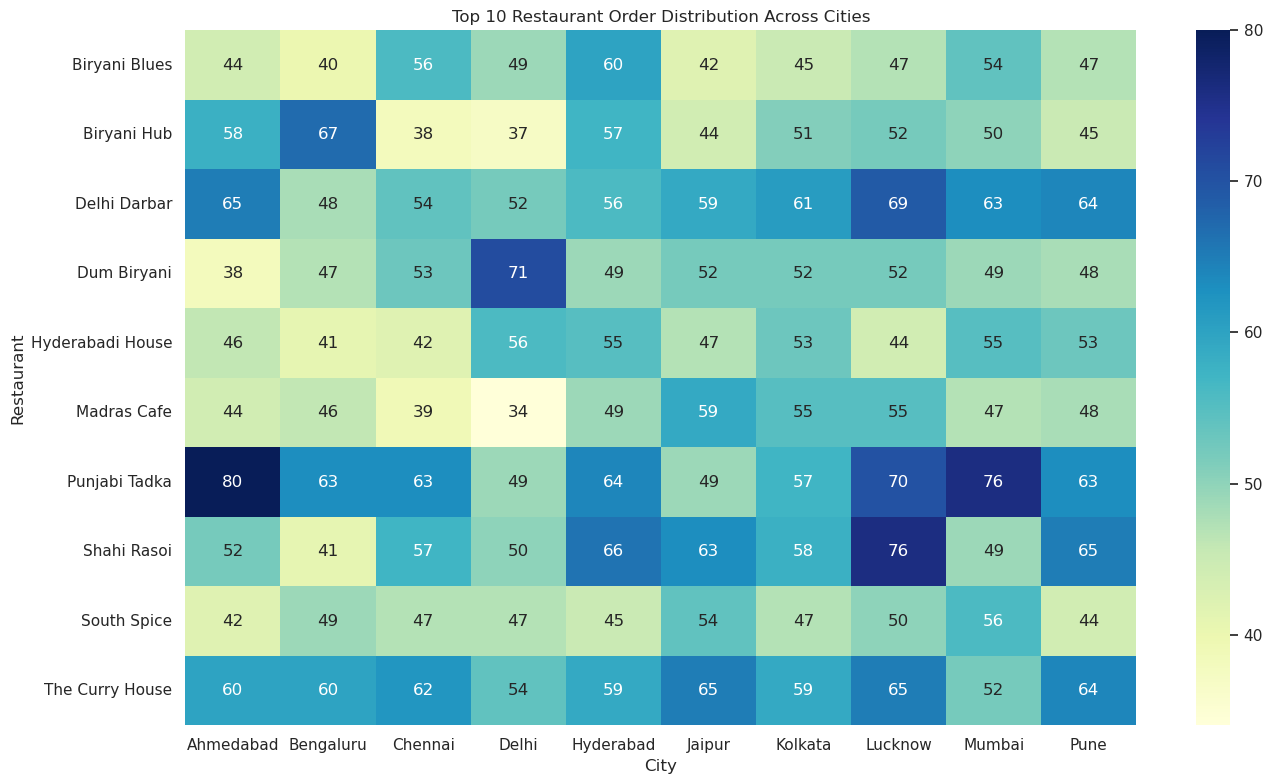

In [47]:
# Identify the top 10 restaurants by total number of orders
top_restaurants = df['Restaurant_Name'].value_counts().head(10).index

# Filter the dataset for these restaurants
restaurant_city_df = df[df['Restaurant_Name'].isin(top_restaurants)]

# Create a city-wise restaurant order count table
restaurant_city_orders = restaurant_city_df.pivot_table(
    index='Restaurant_Name',
    columns='City',
    values='Order_ID',
    aggfunc='count',
    fill_value=0)

print("Restaurant Order Distribution Across Cities:")
print(restaurant_city_orders)

# Visualize using a heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    restaurant_city_orders,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu')

plt.title('Top 10 Restaurant Order Distribution Across Cities')
plt.xlabel('City')
plt.ylabel('Restaurant')
plt.tight_layout()
plt.show()